# Spatial-Temporal Feature Extraction via Deep Autoencoders


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

# Ensure project root is in Python path
cur_dir = Path('.').resolve()
project_root = cur_dir.parent if cur_dir.name == 'notebooks' else cur_dir
src_path = project_root / 'src'
for p_dir in [str(project_root), str(src_path)]:
    if p_dir not in sys.path:
        sys.path.insert(0, p_dir)

from dss.data_generation.simulator import generate_dataset
from dss.feature_extraction.snapshots import build_snapshots_from_df
from dss.feature_extraction.autoencoder import Autoencoder
from dss.feature_extraction.train import train_autoencoder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device configured: {device}")

✅ Device configured: cpu


##  Snapshot Vector Assembly & Scaling


In [2]:
# Generate dataset
channel_df, _, _ = generate_dataset("normal", seed=42, save=False)

# Build multi-channel snapshot vectors
snapshots, ts_list = build_snapshots_from_df(channel_df)
print(f"Snapshot Tensor Shape: {snapshots.shape} (Time Steps x Features per step)")

# Split into Train (80%) and Test (20%)
split_idx = int(len(snapshots) * 0.8)
X_train = snapshots[:split_idx]
X_test = snapshots[split_idx:]

print(f"Train snapshots: {X_train.shape}, Test snapshots: {X_test.shape}")

Snapshot Tensor Shape: (4032, 64) (Time Steps x Features per step)
Train snapshots: (3225, 64), Test snapshots: (807, 64)


##  Autoencoder Neural Network Training


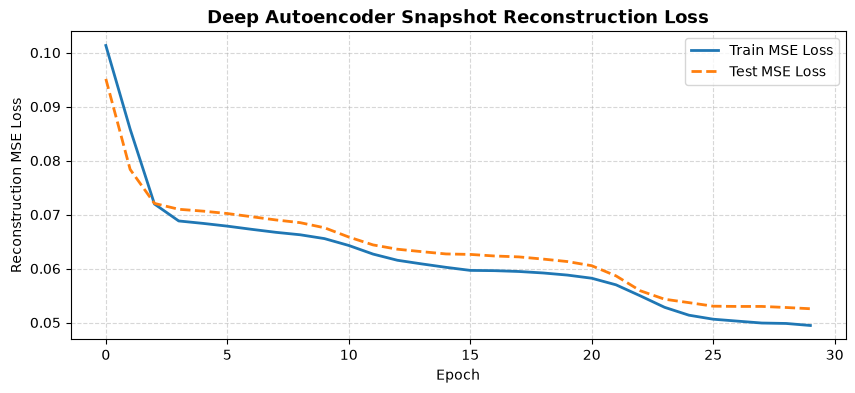

In [3]:
input_dim = snapshots.shape[1]  # 64
bottleneck_dim = 8            # 8 latent bottleneck features

ae_model = Autoencoder(input_dim=input_dim, latent_dim=bottleneck_dim).to(device)

# Train Autoencoder
ae_model, history = train_autoencoder(
    model=ae_model,
    X_train=X_train,
    X_val=X_test,
    epochs=30,
    batch_size=128,
    lr=1e-3,
    device=str(device)
)

# Plot MSE Reconstruction Loss
plt.figure(figsize=(10, 4))
plt.plot(history["train_loss"], label="Train MSE Loss", linewidth=2)
plt.plot(history["val_loss"], label="Test MSE Loss", linewidth=2, linestyle="--")
plt.title("Deep Autoencoder Snapshot Reconstruction Loss", fontsize=13, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Visualizing Snapshot Reconstruction Performance


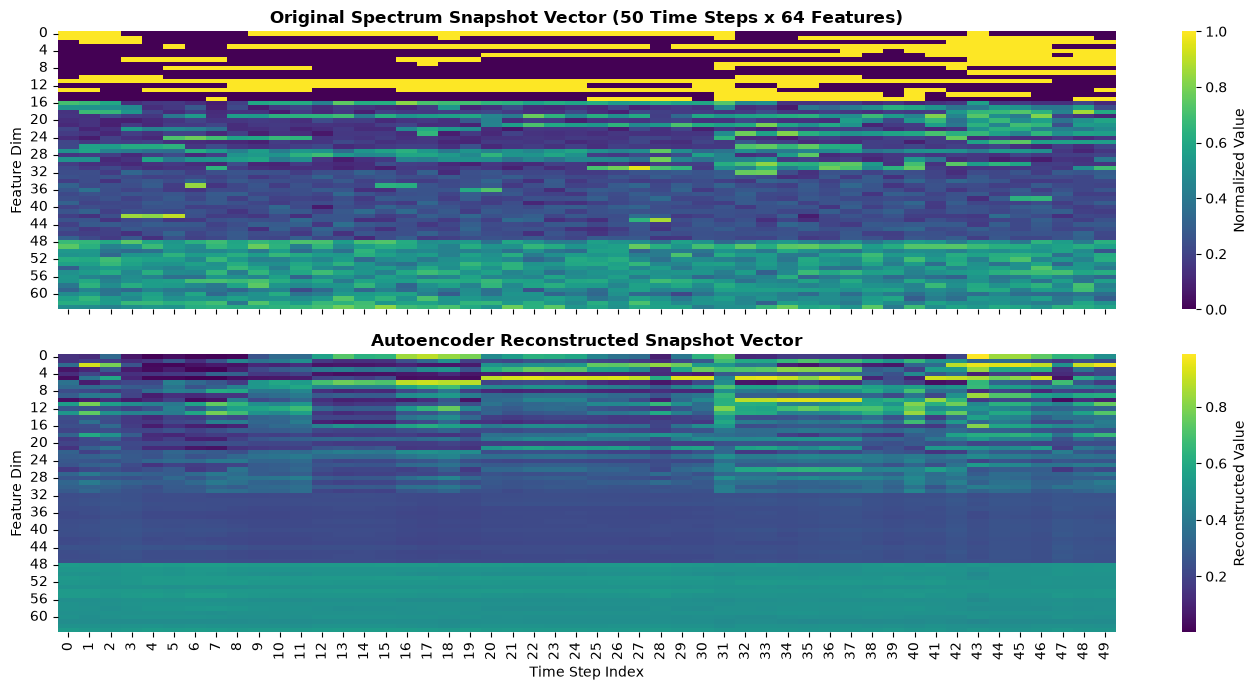

In [4]:
ae_model.eval()
with torch.no_grad():
    sample_input = torch.tensor(X_test[:50], dtype=torch.float32).to(device)
    encoded_features = ae_model.encode(sample_input)
    _, reconstructed = ae_model(sample_input)
    reconstructed = reconstructed.cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

sns.heatmap(X_test[:50].T, ax=axes[0], cmap="viridis", cbar_kws={'label': 'Normalized Value'})
axes[0].set_title("Original Spectrum Snapshot Vector (50 Time Steps x 64 Features)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Feature Dim")

sns.heatmap(reconstructed.T, ax=axes[1], cmap="viridis", cbar_kws={'label': 'Reconstructed Value'})
axes[1].set_title("Autoencoder Reconstructed Snapshot Vector", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Time Step Index")
axes[1].set_ylabel("Feature Dim")

plt.tight_layout()
plt.show()

## Bottleneck Feature Extraction & Embedding Export


In [5]:
with torch.no_grad():
    full_input = torch.tensor(snapshots, dtype=torch.float32).to(device)
    latent_embeddings = ae_model.encode(full_input).cpu().numpy()

print(f" Feature Extraction Complete!")
print(f"Extracted Latent Embeddings Shape: {latent_embeddings.shape} (T x 8 features)")

# Display latent bottleneck feature values for first 5 time steps
latent_df = pd.DataFrame(latent_embeddings, columns=[f"latent_feat_{i+1}" for i in range(8)])
latent_df.head()

 Feature Extraction Complete!
Extracted Latent Embeddings Shape: (4032, 8) (T x 8 features)


,latent_feat_1,latent_feat_2,latent_feat_3,latent_feat_4,latent_feat_5,latent_feat_6,latent_feat_7,latent_feat_8
0,-2.112712,-1.433630,-2.898389,-2.559327,-0.828889,-2.067581,0.302231,0.632015
1,-2.510687,-1.764382,-3.381638,-2.723065,-1.024495,-2.440395,0.230067,0.810785
2,-1.809100,-1.531111,-2.528468,-2.729970,-0.701277,-2.828175,-1.245632,0.472624
3,-1.856434,-1.420319,-2.525392,-2.639666,-0.669356,-2.750668,-1.284805,0.542762
4,-1.907411,-2.145450,-3.016657,-1.867671,-1.391100,-2.053787,-0.389307,0.074814
